In [1]:
import numpy as np
import matplotlib.pyplot as plt

import os
import pandas as pd
# import colorednoise as cn
import scipy.stats as stats

from tqdm import tqdm
from statsmodels.tsa.seasonal import seasonal_decompose, STL

from scipy.fft import fft, rfft
from scipy.fft import fftfreq, rfftfreq

# Functions

In [2]:
def plot_shifts(data_stream,idx_list,drift_detected,label,color,text= True):
    plt.figure(figsize=(10,5))
    plt.plot(data_stream)
    plt.plot(idx_list, drift_detected, 'o', label = label, color = color)
    if text:
        for i in range(len(idx_list)):
            plt.text(idx_list[i], drift_detected[i], str(idx_list[i]), fontsize=12)
  

    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    # plt.savefig(f'ADWIN_FIGS/{label}_Abrupt_Sergi.png')

In [3]:
#read txt file as a list
def read_txt_file(file_name):
    with open(file_name) as f:
        lines = f.readlines()
    return [int(x.strip()) for x in lines]

In [4]:
def add_colored_noise(data,beta,deviation):
    y_simple = cn.powerlaw_psd_gaussian(beta, len(data))
    y_simple_scaled=y_simple*data*deviation
    added_noise=y_simple_scaled+data
    for i in range(len(added_noise)):
        if added_noise[i]<0:
            added_noise[i]=data[i]
    return added_noise

# Datasets

In [5]:
def generate_ar_series(alpha, sigma_sq, length):
    """Generates an AR(p) time series.

    Args:
        alpha (list): The AR parameters [α1, α2, ..., αp].
        sigma_sq (float): The variance (σ²) of the white noise.
        length (int): The length of the time series.

    Returns:
        pd.Series: The generated AR time series.
    """

    p = len(alpha)  # Order of the AR model
    series = np.zeros(length)
    noise = np.random.normal(0, sigma_sq, length)  # Generate white noise

    # Generate initial values (first p values)
    for t in range(p):
        series[t] = np.random.normal(0, 1)  # Or any other initialization

    # Generate the rest of the time series
    for t in range(p, length):
        ar_sum = 0
        for i in range(p):
            ar_sum += alpha[i] * series[t - i - 1]
        series[t] = ar_sum + noise[t]

    return pd.Series(series)


In [6]:
def generate_ar_non_linear_series(alpha, sigma_sq, length):
    """
    Generates a nonlinear AR(p) time series.

    Args:
        alpha (list): The AR parameters [α1, α2, ..., αp].
        sigma_sq (float): The variance (σ²) of the white noise.
        length (int): The length of the time series.

    Returns:
        pd.Series: The generated nonlinear AR time series.
    """

    p = len(alpha)  # Order of the AR model
    series = np.zeros(length)
    
    # Generate Gaussian noise
    # np.random.seed(42)  # For reproducibility
    noise = np.random.normal(0, sigma_sq, length)  # Generate white noise

    # Initialize the time series
    x = np.zeros(length)

    # Compute the time series
    for t in range(2, length):
        x[t] = (noise[t] - alpha[0] * noise[t - 1] + alpha[1]* noise[t - 2] +
                alpha[2] * noise[t - 1] * noise[t - 2] - alpha[3] * noise[t - 2]**2)

    return pd.Series(x)

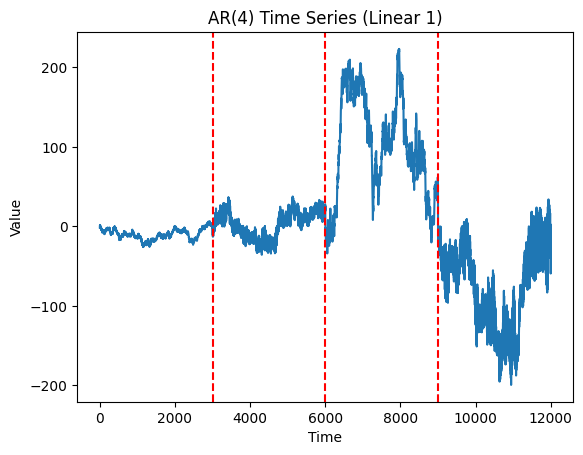

In [7]:
import random
# Generate a time series from Linear 1
alpha = [0.9, -0.2, 0.8, -0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [1.5, -0.4, -0.3, 0.2]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.4, 0.4, -0.7]
sigma_sq4 = 3.5

np.random.seed(41)
series = generate_ar_series(alpha, sigma_sq, 3000)
series2 = generate_ar_series(alpha2, sigma_sq2, 3000)
series3 = generate_ar_series(alpha3, sigma_sq3, 3000)
series4 = generate_ar_series(alpha4, sigma_sq4, 3000)

x = np.concatenate([series, series2, series3, series4])
data_stream = x
plt.plot(data_stream)
plt.axvline(x=len(series), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2)+len(series3), color='r', linestyle='--')
plt.title("AR(4) Time Series (Linear 1)")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

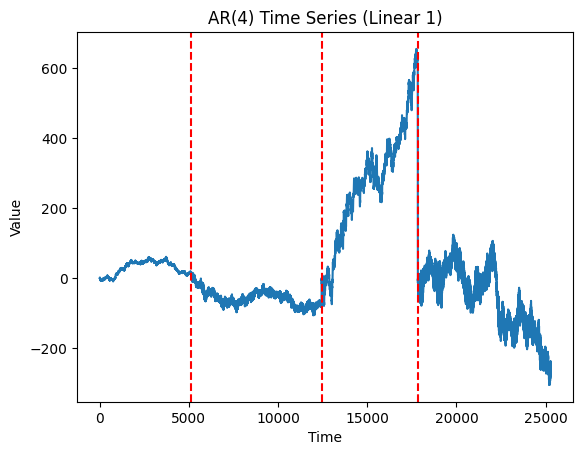

In [8]:
import random
# Generate a time series from Linear 1
alpha = [0.9, -0.2, 0.8, -0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [1.5, -0.4, -0.3, 0.2]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.4, 0.4, -0.7]
sigma_sq4 = 3.5

np.random.seed(42)
series = generate_ar_series(alpha, sigma_sq, random.randint(1000, 10000))
series2 = generate_ar_series(alpha2, sigma_sq2, random.randint(1000, 10000))
series3 = generate_ar_series(alpha3, sigma_sq3, random.randint(1000, 10000))
series4 = generate_ar_series(alpha4, sigma_sq4, random.randint(1000, 10000))

x = np.concatenate([series, series2, series3, series4])
data_stream = x
plt.plot(data_stream)
plt.axvline(x=len(series), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2)+len(series3), color='r', linestyle='--')
plt.title("AR(4) Time Series (Linear 1)")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

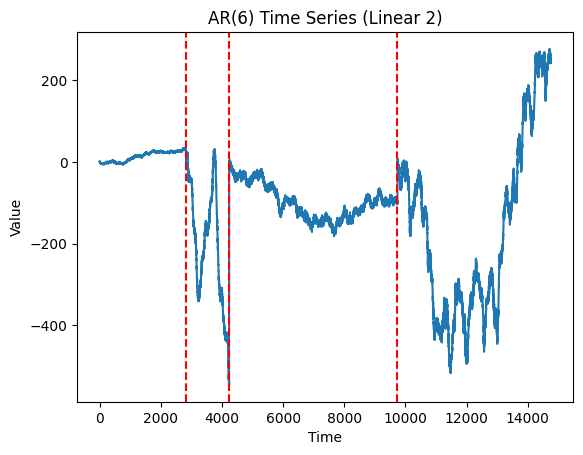

In [9]:
import random
# Generate a time series from Linear 2
alpha = [1.1, -0.6, 0.8, -0.5, -0.1, 0.3]
sigma_sq = 0.5
alpha2 = [-0.1, 1.2, 0.4, 0.3, -0.2, -0.6]
sigma_sq2 = 1.5
alpha3 = [1.2, -0.4, -0.3, 0.7, -0.6, 0.4]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.1, 0.5, 0.2, -0.2, -0.5]
sigma_sq4 = 3.5

random.seed(42)
np.random.seed(42)
series = generate_ar_series(alpha, sigma_sq, random.randint(1000, 10000))
series2 = generate_ar_series(alpha2, sigma_sq2, random.randint(1000, 10000))
series3 = generate_ar_series(alpha3, sigma_sq3, random.randint(1000, 10000))
series4 = generate_ar_series(alpha4, sigma_sq4, random.randint(1000, 10000))

x = np.concatenate([series, series2, series3, series4])
data_stream = x
plt.plot(data_stream)
plt.axvline(x=len(series), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2)+len(series3), color='r', linestyle='--')
plt.title(f"AR({len(alpha)}) Time Series (Linear 2)")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

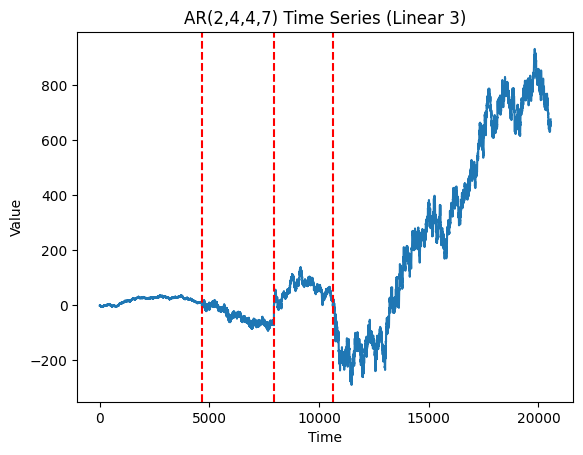

In [10]:
# Generate a time series from Linear 3
alpha = [0.5, 0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [0.9, -0.2, 0.8, -0.5]
sigma_sq3 = 2.5
alpha4 = [0.9, 0.8, -0.6, 0.2, -0.5, -0.2, 0.4]
sigma_sq4 = 3.5

np.random.seed(42)
series = generate_ar_series(alpha, sigma_sq, random.randint(1000, 10000))
series2 = generate_ar_series(alpha2, sigma_sq2, random.randint(1000, 10000))
series3 = generate_ar_series(alpha3, sigma_sq3, random.randint(1000, 10000))
series4 = generate_ar_series(alpha4, sigma_sq4, random.randint(1000, 10000))

x = np.concatenate([series, series2, series3, series4])
data_stream = x
plt.plot(data_stream)
# Add vertical lines at 3000, 6000, and 9000
plt.axvline(x=len(series), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2)+len(series3), color='r', linestyle='--')
plt.title("AR(2,4,4,7) Time Series (Linear 3)")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

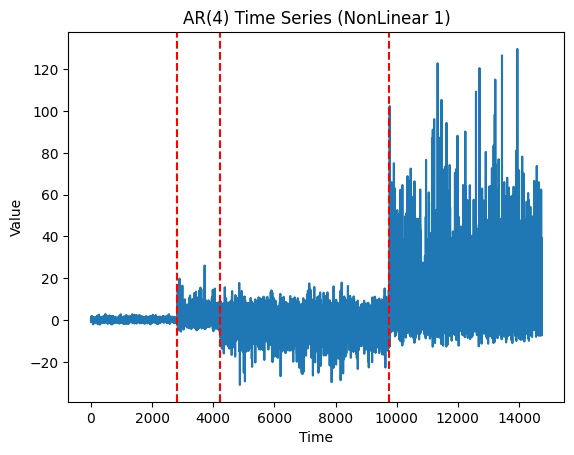

In [11]:
# Generate a time series from nonLinear 1 (nonlinear moving average model)
alpha = [0.9, -0.2, 0.8, -0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [1.5, -0.4, -0.3, 0.2]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.4, 0.4, -0.7]
sigma_sq4 = 3.5

np.random.seed(42)
random.seed(42)
series = generate_ar_non_linear_series(alpha, sigma_sq, random.randint(1000, 10000))
series2 = generate_ar_non_linear_series(alpha2, sigma_sq2, random.randint(1000, 10000))
series3 = generate_ar_non_linear_series(alpha3, sigma_sq3, random.randint(1000, 10000))
series4 = generate_ar_non_linear_series(alpha4, sigma_sq4, random.randint(1000, 10000))

x = np.concatenate([series, series2, series3, series4])
data_stream = x
plt.plot(data_stream)
# Add vertical lines at 3000, 6000, and 9000
plt.axvline(x=len(series), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2)+len(series3), color='r', linestyle='--')
plt.title("AR(4) Time Series (NonLinear 1)")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

In [12]:
def generate_ar_non_linear_series_smooth_transition(alpha, sigma_sq, length):
    """
    Generates a nonlinear AR(p) time series.

    Args:
        alpha (list): The AR parameters [α1, α2, ..., αp].
        sigma_sq (float): The variance (σ²) of the white noise.
        length (int): The length of the time series.

    Returns:
        pd.Series: The generated nonlinear AR time series.
    """

    p = len(alpha)  # Order of the AR model
    
    # Generate Gaussian noise
    # np.random.seed(42)  # For reproducibility
    noise = np.random.normal(0, sigma_sq, length)  # Generate white noise

    # Initialize the time series
    x = np.zeros(length)

    # Compute the time series
    for t in range(4, length):  # Start from t=4 to account for x[t-4]
        x[t] = (alpha[0] * x[t - 1] + alpha[1] * x[t - 2] +  alpha[2] * x[t - 3] + alpha[3] * x[t - 4]) * (1 + np.exp(-10 * x[t - 1]))**(-1) + noise[t]

    return pd.Series(x)

For nonlinear 2 and 3, the formula should be 1+exp (not 10exp)
https://www.diva-portal.org/smash/get/diva2:326676/FULLTEXT01.pdf

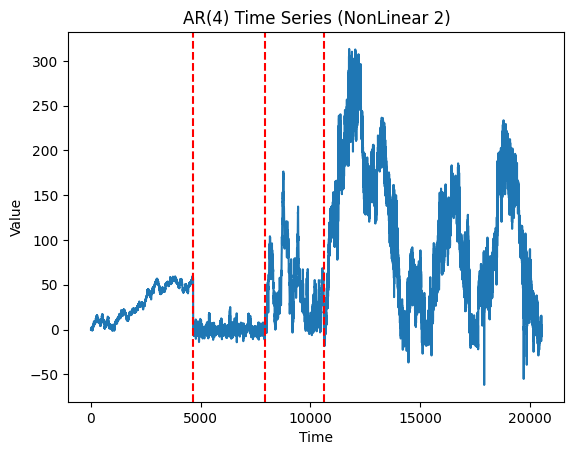

In [13]:
# Generate a time series from nonLinear 2 (nonlinear smooth transition autoregressive model 1)
alpha = [0.9, -0.2, 0.8, -0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [1.5, -0.4, -0.3, 0.2]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.4, 0.4, -0.7]
sigma_sq4 = 3.5

# np.random.seed(42)
series = generate_ar_non_linear_series_smooth_transition(alpha, sigma_sq, random.randint(1000, 10000))
series2 = generate_ar_non_linear_series_smooth_transition(alpha2, sigma_sq2, random.randint(1000, 10000))
series3 = generate_ar_non_linear_series_smooth_transition(alpha3, sigma_sq3, random.randint(1000, 10000))
series4 = generate_ar_non_linear_series_smooth_transition(alpha4, sigma_sq4, random.randint(1000, 10000))

x = np.concatenate([series, series2, series3, series4])
data_stream = x
plt.plot(data_stream)
# Add vertical lines at 3000, 6000, and 9000
plt.axvline(x=len(series), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2)+len(series3), color='r', linestyle='--')
plt.title("AR(4) Time Series (NonLinear 2)")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

In [14]:
data_stream[0:10]

array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.31366406,
        0.54902211,  0.02310267, -0.29654976,  0.11233247, -0.41940433])

The model for nonlinear timesries was adapted based opn second model in https://www.diva-portal.org/smash/get/diva2:326676/FULLTEXT01.pdf and parameters for nonlinear time series 1 and 2

In [15]:
def generate_ar_non_linear_series_smooth_transition_model_2(alpha, sigma_sq, length):
    """
    Generates a nonlinear AR(p) time series.

    Args:
        alpha (list): The AR parameters [α1, α2, ..., αp].
        sigma_sq (float): The variance (σ²) of the white noise.
        length (int): The length of the time series.

    Returns:
        pd.Series: The generated nonlinear AR time series.
    """

    p = len(alpha)  # Order of the AR model
    
    # Generate Gaussian noise
    # np.random.seed(42)  # For reproducibility
    noise = np.random.normal(0, sigma_sq, length)  # Generate white noise

    # Initialize the time series
    x = np.zeros(length)

    # Compute the time series
    for t in range(4, length):  # Start from t=4 to account for x[t-4]
        # x[t] = alpha[0] * x[t - 1] + alpha[1] * x[t - 2] +  (alpha[2] * x[t - 1] + alpha[0] * x[t - 2]) * (1 + np.exp(-10 * x[t - 1]))**(-1) + noise[t] # does not work
        x[t] = alpha[0] * x[t - 1] + alpha[1] * x[t - 2] +  (alpha[2] * x[t - 3] + alpha[3] * x[t - 4]) * (1 - np.exp(-10 * x[t - 1]**(2))) + noise[t]
    return pd.Series(x)

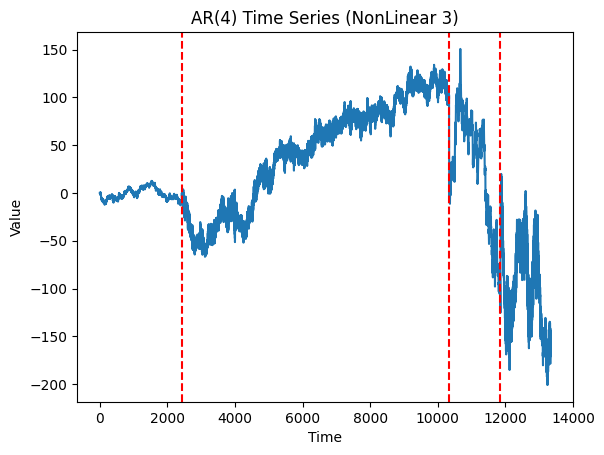

In [16]:
# Generate a time series from nonLinear 3 (nonlinear smooth transition autoregressive model 1)
# alpha = [-0.5, 0.8, -0.2, 0.9]
# sigma_sq = 0.5
# alpha2 = [-0.5, 0.4, 1.4, -0.3]
# sigma_sq2 = 1.5
# alpha3 = [0.2, -0.3, -0.4, 1.5]
# sigma_sq3 = 2.5
# alpha4 = [-0.7, 0.4, 1.4, -0.1]
# sigma_sq4 = 3.5
alpha = [0.9, -0.2, 0.8, -0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [1.5, -0.4, -0.3, 0.2]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.4, 0.4, -0.7]
sigma_sq4 = 3.5

# np.random.seed(42)
series = generate_ar_non_linear_series_smooth_transition_model_2(alpha, sigma_sq, random.randint(1000, 10000))
series2 = generate_ar_non_linear_series_smooth_transition_model_2(alpha2, sigma_sq2, random.randint(1000, 10000))
series3 = generate_ar_non_linear_series_smooth_transition_model_2(alpha3, sigma_sq3, random.randint(1000, 10000))
series4 = generate_ar_non_linear_series_smooth_transition_model_2(alpha4, sigma_sq4, random.randint(1000, 10000))

x = np.concatenate([series, series2, series3, series4])
data_stream = x
plt.plot(data_stream)
# Add vertical lines at 3000, 6000, and 9000
plt.axvline(x=len(series), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2), color='r', linestyle='--')
plt.axvline(x=len(series)+len(series2)+len(series3), color='r', linestyle='--')
plt.title("AR(4) Time Series (NonLinear 3)")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

# Linear dataset

The artificial linear time series data set is composed by **120 time series**, which can be divided into three groups: 
- AR(4) time series affected by changes in the AR parameters and in σ2, 
- AR(6) time series affected by changes in the AR parameters and in σ2 and 
- AR(p) time series affected  by changes in the order p, in the AR parameters and in σ2.

 These time series are affected by 3 drifts. In each group, half of the time series (60) are affected by abrupt concept drifts
 and half (60) is affected by gradual drifts. Table I reports the AR
 parameters for each group of linear time series. 
 
- **Abrupt drifts**  were simulated by an instantaneous change in the parameters.
 - **Gradual drifts** were simulated by inserting a gradual change in the parameters. The size of a gradual change corresponds
 to 10% of the data points of the new concept.

For abrupt concept drifts, we take generate 20 times linear 1, 20 times linear 2, and 20 times linear 3:

In [17]:
min_interval = 1000
max_interval = 5000


# Generate a time series from Linear 1
alpha = [0.9, -0.2, 0.8, -0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [1.5, -0.4, -0.3, 0.2]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.4, 0.4, -0.7]
sigma_sq4 = 3.5

filename = f'time_series_linear_abrupt_100.csv'
if os.path.exists(filename):
    os.remove(filename)

filename_labels = f'drift_labels_linear_abrupt_100.csv'
if os.path.exists(filename_labels):
    os.remove(filename_labels)

for i in range(34):
    # np.random.seed(42)
    series = generate_ar_series(alpha, sigma_sq, random.randint(min_interval, max_interval))
    series2 = generate_ar_series(alpha2, sigma_sq2, random.randint(min_interval, max_interval))
    series3 = generate_ar_series(alpha3, sigma_sq3, random.randint(min_interval, max_interval))
    series4 = generate_ar_series(alpha4, sigma_sq4, random.randint(min_interval, max_interval))
    x = np.concatenate([series, series2, series3, series4])
    drift_labels = [len(series), len(series)+len(series2),len(series)+len(series2)+len(series3)]
    with open(f"{filename}", "a") as file:
        np.savetxt(file, [x], delimiter=",", fmt="%.6f")
    with open(f"{filename_labels}", "a") as file:
        np.savetxt(file, [drift_labels], delimiter=",", fmt="%.6f")

# Generate a time series from Linear 2
alpha = [1.1, -0.6, 0.8, -0.5, -0.1, 0.3]
sigma_sq = 0.5
alpha2 = [-0.1, 1.2, 0.4, 0.3, -0.2, -0.6]
sigma_sq2 = 1.5
alpha3 = [1.2, -0.4, -0.3, 0.7, -0.6, 0.4]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.1,0.5, 0.2, -0.2, -0.5]
sigma_sq4 = 3.5

for i in range(33):
    # np.random.seed(42)
    series = generate_ar_series(alpha, sigma_sq, random.randint(min_interval, max_interval))
    series2 = generate_ar_series(alpha2, sigma_sq2, random.randint(min_interval, max_interval))
    series3 = generate_ar_series(alpha3, sigma_sq3, random.randint(min_interval, max_interval))
    series4 = generate_ar_series(alpha4, sigma_sq4, random.randint(min_interval, max_interval))

    x = np.concatenate([series, series2, series3, series4])
    drift_labels = [len(series), len(series)+len(series2),len(series)+len(series2)+len(series3)]
    with open(f"{filename}", "a") as file:
        np.savetxt(file, [x], delimiter=",", fmt="%.6f")
    with open(f"{filename_labels}", "a") as file:
        np.savetxt(file, [drift_labels], delimiter=",", fmt="%.6f")

# Generate a time series from Linear 3

alpha = [0.5, 0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [0.9, -0.2, 0.8, -0.5]
sigma_sq3 = 2.5
alpha4 = [0.9, 0.8, -0.6, 0.2, -0.5, -0.2, 0.4]
sigma_sq4 = 3.5

for i in range(33):
    # np.random.seed(42)
    series = generate_ar_series(alpha, sigma_sq, random.randint(min_interval, max_interval))
    series2 = generate_ar_series(alpha2, sigma_sq2, random.randint(min_interval, max_interval))
    series3 = generate_ar_series(alpha3, sigma_sq3, random.randint(min_interval, max_interval))
    series4 = generate_ar_series(alpha4, sigma_sq4, random.randint(min_interval, max_interval))

    x = np.concatenate([series, series2, series3, series4])
    drift_labels = [len(series), len(series)+len(series2),len(series)+len(series2)+len(series3)]
    with open(f"{filename}", "a") as file:
        np.savetxt(file, [x], delimiter=",", fmt="%.6f")
    with open(f"{filename_labels}", "a") as file:
        np.savetxt(file, [drift_labels], delimiter=",", fmt="%.6f")      


In [18]:
def load_variable_column_csv(file_path, delimiter=','):
    # The max column count a line in the file could have
    largest_column_count = 0

    # Loop the data lines
    with open(file_path, 'r') as temp_f:
        # Read the lines
        lines = temp_f.readlines()

        for l in lines:
            # Count the column count for the current line
            column_count = len(l.split(delimiter)) + 1
            
            # Set the new most column count
            largest_column_count = column_count if largest_column_count < column_count else largest_column_count

    # Generate column names (will be 0, 1, 2, ..., largest_column_count - 1)
    column_names = [i for i in range(0, largest_column_count)]

    # Read csv
    return pd.read_csv(file_path, header=None, delimiter=delimiter, names=column_names)

In [19]:
import pandas as pd

# Attempt to load the file while ignoring extra columns
data = load_variable_column_csv('time_series_linear_abrupt_100.csv')

print(data.head())

      0         1         2         3         4         5         6      \
0 -0.087947 -1.823688  0.659093  0.617422  0.274321  1.770795  1.758162   
1 -1.612215 -0.692043  0.712057  1.162466  1.050871  0.646574  0.464742   
2  0.045178 -0.312315  0.890168  1.741596  0.409195  0.784884  1.592834   
3  0.027456 -1.101987  0.426424  0.232550 -0.312875  0.789568  0.941025   
4 -1.300347 -0.327194  0.377212 -0.666402  0.441547  0.578050  0.159014   

      7         8         9      ...  17619  17620  17621  17622  17623  \
0  1.307049  2.739851  3.890226  ...    NaN    NaN    NaN    NaN    NaN   
1  0.751341  0.440207  0.243876  ...    NaN    NaN    NaN    NaN    NaN   
2  0.581600  0.492915  1.847313  ...    NaN    NaN    NaN    NaN    NaN   
3  1.030818  1.687796  1.529236  ...    NaN    NaN    NaN    NaN    NaN   
4  0.955987  1.334357  1.070556  ...    NaN    NaN    NaN    NaN    NaN   

   17624  17625  17626  17627  17628  
0    NaN    NaN    NaN    NaN    NaN  
1    NaN    NaN    N

In [20]:
# Attempt to load the file while ignoring extra columns
labels_linear = load_variable_column_csv('drift_labels_linear_abrupt_100.csv')

print(labels_linear.head())

        0       1        2   3
0  1383.0  3278.0   5230.0 NaN
1  3465.0  4573.0   7871.0 NaN
2  3932.0  7593.0  11465.0 NaN
3  2718.0  4620.0   7459.0 NaN
4  2139.0  6454.0  11014.0 NaN


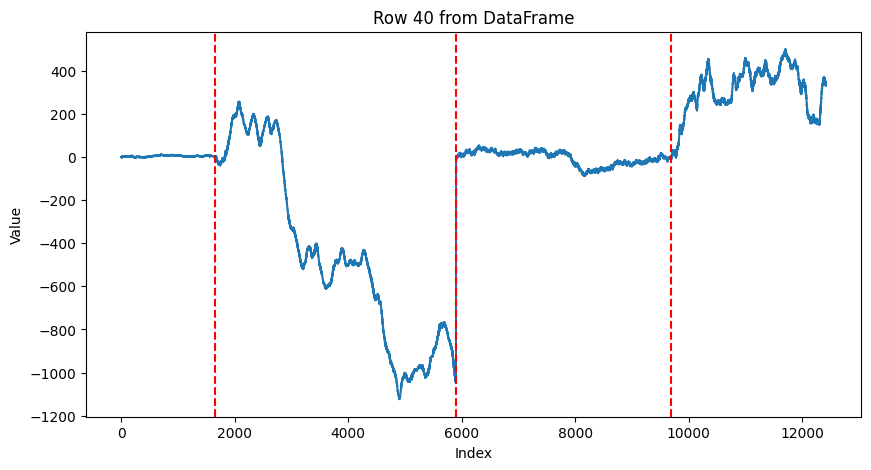

In [21]:
# Extract row 20 from the dataframe
item = 40
row_20 = data.iloc[item, :].dropna()
row_labels = labels_linear.iloc[item, :].dropna()
# Plot the row
plt.figure(figsize=(10, 5))
plt.plot(row_20.values)
for value in row_labels:
    plt.axvline(x=value, color='red', linestyle='--', label=f"Line at {value}")
plt.title(f"Row {item} from DataFrame")
plt.xlabel("Index")
plt.ylabel("Value")
# plt.legend()
plt.show()

# Nonlinear dataset

For abrupt concept drifts, we take generate 20 times nonlinear 1, 20 times nonlinear 2, and 20 times nonlinear 3:

In [22]:

# Generate a time series from NonLinear 1
alpha = [0.9, -0.2, 0.8, -0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [1.5, -0.4, -0.3, 0.2]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.4, 0.4, -0.7]
sigma_sq4 = 3.5

filename = f'time_series_nonlinear_abrupt_100.csv'
if os.path.exists(filename):
    os.remove(filename)

filename_labels = f'drift_labels_nonlinear_abrupt_100.csv'
if os.path.exists(filename_labels):
    os.remove(filename_labels)

for i in range(34):
    series = generate_ar_non_linear_series(alpha, sigma_sq, random.randint(min_interval, max_interval))
    series2 = generate_ar_non_linear_series(alpha2, sigma_sq2, random.randint(min_interval, max_interval))
    series3 = generate_ar_non_linear_series(alpha3, sigma_sq3, random.randint(min_interval, max_interval))
    series4 = generate_ar_non_linear_series(alpha4, sigma_sq4, random.randint(min_interval, max_interval))
    x = np.concatenate([series, series2, series3, series4])
    drift_labels = [len(series), len(series)+len(series2),len(series)+len(series2)+len(series3)]
    with open(f"{filename}", "a") as file:
        np.savetxt(file, [x], delimiter=",", fmt="%.6f")
    with open(f"{filename_labels}", "a") as file:
        np.savetxt(file, [drift_labels], delimiter=",", fmt="%.6f")

# Generate a time series from NonLinear 2
alpha = [0.9, -0.2, 0.8, -0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [1.5, -0.4, -0.3, 0.2]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.4, 0.4, -0.7]
sigma_sq4 = 3.5

for i in range(33):
    # np.random.seed(42)
    series = generate_ar_non_linear_series_smooth_transition(alpha, sigma_sq, random.randint(min_interval, max_interval))
    series2 = generate_ar_non_linear_series_smooth_transition(alpha2, sigma_sq2, random.randint(min_interval, max_interval))
    series3 = generate_ar_non_linear_series_smooth_transition(alpha3, sigma_sq3, random.randint(min_interval, max_interval))
    series4 = generate_ar_non_linear_series_smooth_transition(alpha4, sigma_sq4, random.randint(min_interval, max_interval))
    x = np.concatenate([series, series2, series3, series4])
    drift_labels = [len(series), len(series)+len(series2),len(series)+len(series2)+len(series3)]
    
    with open(f"{filename}", "a") as file:
        np.savetxt(file, [x], delimiter=",", fmt="%.6f")
    with open(f"{filename_labels}", "a") as file:
        np.savetxt(file, [drift_labels], delimiter=",", fmt="%.6f")

# Generate a time series from NonLinear 3
alpha = [0.9, -0.2, 0.8, -0.5]
sigma_sq = 0.5
alpha2 = [-0.3, 1.4, 0.4, -0.5]
sigma_sq2 = 1.5
alpha3 = [1.5, -0.4, -0.3, 0.2]
sigma_sq3 = 2.5
alpha4 = [-0.1, 1.4, 0.4, -0.7]
sigma_sq4 = 3.5

for i in range(33):
    # np.random.seed(42)
    series = generate_ar_non_linear_series_smooth_transition_model_2(alpha, sigma_sq, random.randint(min_interval, max_interval))
    series2 = generate_ar_non_linear_series_smooth_transition_model_2(alpha2, sigma_sq2, random.randint(min_interval, max_interval))
    series3 = generate_ar_non_linear_series_smooth_transition_model_2(alpha3, sigma_sq3, random.randint(min_interval, max_interval))
    series4 = generate_ar_non_linear_series_smooth_transition_model_2(alpha4, sigma_sq4, random.randint(min_interval, max_interval))
    x = np.concatenate([series, series2, series3, series4])
    drift_labels = [len(series), len(series)+len(series2),len(series)+len(series2)+len(series3)]
    with open(f"{filename}", "a") as file:
        np.savetxt(file, [x], delimiter=",", fmt="%.6f")
    with open(f"{filename_labels}", "a") as file:
        np.savetxt(file, [drift_labels], delimiter=",", fmt="%.6f")     


/tmp/ipykernel_2363434/468555364.py:25: RuntimeWarning: overflow encountered in exp
  x[t] = (alpha[0] * x[t - 1] + alpha[1] * x[t - 2] +  alpha[2] * x[t - 3] + alpha[3] * x[t - 4]) * (1 + np.exp(-10 * x[t - 1]))**(-1) + noise[t]


In [23]:
import pandas as pd

# Attempt to load the file while ignoring extra columns
data_nonlinear = load_variable_column_csv('time_series_nonlinear_abrupt_100.csv')

print(data_nonlinear.head())

   0      1         2         3         4         5         6         7      \
0    0.0    0.0 -0.732014  0.489567  1.392962 -0.237058  0.319464 -0.598974   
1    0.0    0.0 -0.187011  0.328834 -0.003575  2.392591 -1.452797 -0.369540   
2    0.0    0.0  0.852639 -0.347086  0.672348  0.281915  0.434435 -0.221647   
3    0.0    0.0  0.418982 -0.353921  0.058076 -0.286079  0.006814  1.413629   
4    0.0    0.0  1.075287 -0.583784  0.335959  0.006115 -0.549602 -0.091044   

      8         9      ...  16682  16683  16684  16685  16686  16687  16688  \
0  0.766514 -0.700229  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1  0.629469  0.882440  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
2  0.515670 -0.292690  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
3 -1.453035  0.757334  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
4  2.166838 -1.867643  ...    NaN    NaN    NaN    NaN    NaN    NaN    NaN   

   16689  16690  16691  
0    NaN    NaN    NaN  


In [24]:
# Attempt to load the file while ignoring extra columns
labels_nonlinear = load_variable_column_csv('drift_labels_nonlinear_abrupt_100.csv')

print(labels_nonlinear.head())

        0       1        2   3
0  4208.0  7484.0  11195.0 NaN
1  2993.0  4627.0   6404.0 NaN
2  1891.0  6858.0   8097.0 NaN
3  4013.0  7233.0   8482.0 NaN
4  2284.0  3518.0   4723.0 NaN


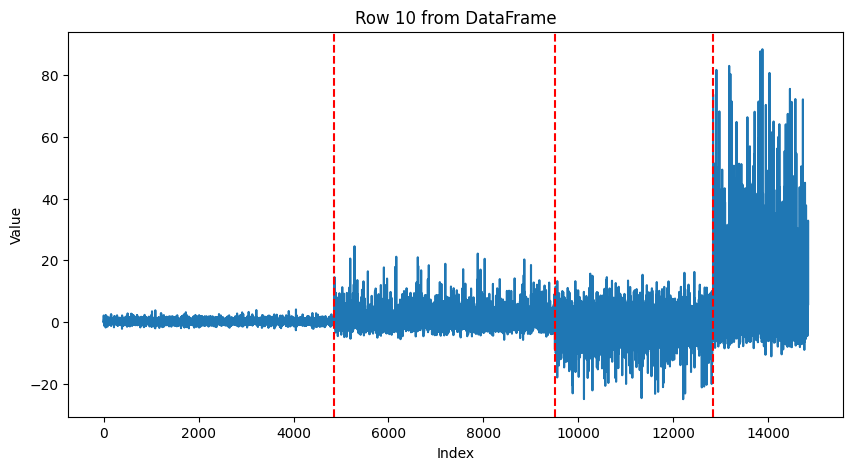

In [25]:
# Extract row 20 from the dataframe
item = 10
row_20 = data_nonlinear.iloc[item, :].dropna()
row_labels = labels_nonlinear.iloc[item, :].dropna()

# Plot the row
plt.figure(figsize=(10, 5))
plt.plot(row_20.values)
plt.title(f"Row {item} from DataFrame")
for value in row_labels:
    plt.axvline(x=value, color='red', linestyle='--', label=f"Line at {value}")
plt.xlabel("Index")
plt.ylabel("Value")
plt.show()